# Integrasi Chatbot Sejarah Indonesia

IR based

BM25

Rule-based Answer Extraction

Tanpa LLM

In [1]:
import sys
from pathlib import Path

folder_aktif = Path.cwd().resolve()

ROOT = next(
    (
        p for p in [folder_aktif, *folder_aktif.parents]
        if (p / "data" / "processed" /
            "korpus_kalimat_final.json").is_file()
        and (p / "question_processing" /
             "question_processing.py").is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Direktori utama proyek tidak ditemukan."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Root proyek:", ROOT)

Root proyek: C:\Users\Shatara Belva M\Videos\pba-qa-sejarah-indonesia


## 1. Persiapan modul dan korpus

Load modul : QP, PR, AP, korpus after preprocessing

In [2]:
import csv
import json
from pathlib import Path

from question_processing.question_processing import process_question
from passage_retrieval.passage_retrieval import cari
from answer_processing.answer_processing import ambil_jawaban

# Konfigurasi sistem
K = 20

K_VALUES = [1, 3, 5, 10, 20]

USE_NORMALIZED_QUERY = True

# Lokasi korpus
CORPUS_FILE = (
    ROOT
    / "data"
    / "processed"
    / "korpus_kalimat_final.json"
)

# Memuat korpus hasil preprocessing
with CORPUS_FILE.open(encoding="utf-8") as file:
    kalimat_korpus = json.load(file)["kalimat"]

# Informasi konfigurasi
print("=" * 50)
print("PERSIAPAN SISTEM QUESTION ANSWERING")
print("=" * 50)

print(f"Jumlah kalimat    : {len(kalimat_korpus)}")
print(f"Metode            : BM25")
print(f"Default Top-k     : {K}")
print(f"Variasi Top-k     : {K_VALUES}")
print(f"Normalized Query  : {USE_NORMALIZED_QUERY}")

print("\nSistem siap digunakan.")

PERSIAPAN SISTEM QUESTION ANSWERING
Jumlah kalimat    : 3140
Metode            : BM25
Default Top-k     : 20
Variasi Top-k     : [1, 3, 5, 10, 20]
Normalized Query  : True

Sistem siap digunakan.


## 2. Dataset dan Ground Truth

In [3]:
SOAL_UJI = [
    {
        "id_dokumen": "D01",
        "pertanyaan": "Sumber daya alam apakah yang menjadi sasaran utama Jepang dalam pendudukannya di Hindia Belanda?",
        "jenis_acuan": "apa",
        "jawaban_acuan": "Minyak bumi",
        "blok_acuan": "D01-B0009"
    },
    {
        "id_dokumen": "D02",
        "pertanyaan": "Dimana masa persidangan pertama BPUPK dibuka?",
        "jenis_acuan": "dimana",
        "jawaban_acuan": "Gedung Chuo Sangi In di Jakarta",
        "blok_acuan": "D02-B0010"
    },
    {
        "id_dokumen": "D03",
        "pertanyaan": "Siapa yang ditunjuk PPKI sebagai wakil presiden pertama Indonesia?",
        "jenis_acuan": "siapa",
        "jawaban_acuan": "Mohammad Hatta",
        "blok_acuan": "D03-B0001"
    },
    {
        "id_dokumen": "D04",
        "pertanyaan": "Siapa yang memberikan julukan \"Piagam Jakarta\" kepada naskah usulan Mukadimah Undang-Undang Dasar Indonesia?",
        "jenis_acuan": "siapa",
        "jawaban_acuan": "Mohammad Yamin",
        "blok_acuan": "D04-B0017"
    },
    {
        "id_dokumen": "D05",
        "pertanyaan": "Pada tanggal berapa Soekarno dan Mohammad Hatta dibawa ke Rengasdengklok?",
        "jenis_acuan": "kapan",
        "jawaban_acuan": "16 Agustus 1945",
        "blok_acuan": "D05-B0001"
    },
    {
        "id_dokumen": "D06",
        "pertanyaan": "Apa nama kapal tempat Jepang secara resmi menyerah kepada Sekutu?",
        "jenis_acuan": "apa",
        "jawaban_acuan": "USS Missouri",
        "blok_acuan": "D06-B0007"
    },
    {
        "id_dokumen": "D07",
        "pertanyaan": "Ke kota manakah Soekarno diasingkan bersama keluarganya pada tahun 1934?",
        "jenis_acuan": "dimana",
        "jawaban_acuan": "Ende",
        "blok_acuan": "D07-B0019"
    },
    {
        "id_dokumen": "D08",
        "pertanyaan": "Kapan Mohammad Hatta lahir?",
        "jenis_acuan": "kapan",
        "jawaban_acuan": "12 Agustus 1902",
        "blok_acuan": "D08-B0004"
    },
    {
        "id_dokumen": "D09",
        "pertanyaan": "Pada tahun berapa Sutan Sjahrir mendirikan Partai Sosialis Indonesia?",
        "jenis_acuan": "kapan",
        "jawaban_acuan": "1948",
        "blok_acuan": "D09-B0002"
    },
    {
        "id_dokumen": "D10",
        "pertanyaan": "Pada tanggal berapa Soebardjo dilantik sebagai Menteri Luar Negeri pada Kabinet Presidensial?",
        "jenis_acuan": "kapan",
        "jawaban_acuan": "18 Agustus 1945",
        "blok_acuan": "D10-B0011"
    },
    {
        "id_dokumen": "D11",
        "pertanyaan": "Dimana Fatmawati dilahirkan?",
        "jenis_acuan": "dimana",
        "jawaban_acuan": "Bengkulu",
        "blok_acuan": "D11-B0002"
    },
    {
        "id_dokumen": "D12",
        "pertanyaan": "Siapa yang terpilih menjadi panglima Tentara Keamanan Rakyat?",
        "jenis_acuan": "siapa",
        "jawaban_acuan": "Sudirman",
        "blok_acuan": "D12-B0009"
    },
    {
        "id_dokumen": "D13",
        "pertanyaan": "Siapa komandan pasukan Britania yang tewas dalam baku tembak pada 30 Oktober 1945 di Surabaya?",
        "jenis_acuan": "siapa",
        "jawaban_acuan": "Brigadir A. W. S. Mallaby",
        "blok_acuan": "D13-B0002"
    },
    {
        "id_dokumen": "D14",
        "pertanyaan": "Siapa anggota milisi BRI yang meledakkan gudang amunisi di Dayeuhkolot dengan dinamit?",
        "jenis_acuan": "siapa",
        "jawaban_acuan": "Muhammad Toha",
        "blok_acuan": "D14-B0007"
    },
    {
        "id_dokumen": "D15",
        "pertanyaan": "Di daerah mana pasukan Belanda melakukan pendaratan dalam Operasi Produk Utara?",
        "jenis_acuan": "dimana",
        "jawaban_acuan": "Pasir Poetih, Situbondo",
        "blok_acuan": "D15-B0005"
    },
    {
        "id_dokumen": "D16",
        "pertanyaan": "Operasi militer Belanda yang dikenal dengan sebutan Operasi Gagak dilancarkan pada bulan apa?",
        "jenis_acuan": "kapan",
        "jawaban_acuan": "Desember 1948",
        "blok_acuan": "D16-B0001"
    },
    {
        "id_dokumen": "D17",
        "pertanyaan": "Siapakah Letkol yang memimpin pasukan dari sektor barat hingga ke batas Malioboro dalam Serangan Umum 1 Maret 1949?",
        "jenis_acuan": "siapa",
        "jawaban_acuan": "Letkol Soeharto",
        "blok_acuan": "D17-B0004"
    },
    {
        "id_dokumen": "D18",
        "pertanyaan": "Siapa yang bertindak sebagai perantara pada tahap awal Perundingan Linggajati?",
        "jenis_acuan": "siapa",
        "jawaban_acuan": "Lord Killearn",
        "blok_acuan": "D18-B0013"
    },
    {
        "id_dokumen": "D19",
        "pertanyaan": "Dimana kapal USS Renville berlabuh saat negosiasi Perjanjian Renville berlangsung?",
        "jenis_acuan": "dimana",
        "jawaban_acuan": "Teluk Jakarta",
        "blok_acuan": "D19-B0002"
    },
    {
        "id_dokumen": "D20",
        "pertanyaan": "Siapa kepala delegasi Republik Indonesia dalam perundingan Roem-Roijen?",
        "jenis_acuan": "siapa",
        "jawaban_acuan": "Mohamad Roem",
        "blok_acuan": "D20-B0002"
    },
    {
        "id_dokumen": "D21",
        "pertanyaan": "Berapa jumlah negara bagian Republik Indonesia Serikat?",
        "jenis_acuan": "berapa",
        "jawaban_acuan": "16 negara bagian",
        "blok_acuan": "D21-B0018"
    }
]
print(f"Daftar soal siap: {len(SOAL_UJI)} pertanyaan")

Daftar soal siap: 21 pertanyaan


## 3. Fungsi chatbot terintegrasi

In [4]:
def jawab_pertanyaan(pertanyaan, k=K):

    # Tahap 1: Question Processing
    informasi = process_question(pertanyaan)

    # Menentukan query untuk retrieval
    if USE_NORMALIZED_QUERY:
        query = informasi["normalized_question"]
    else:
        query = informasi["original_question"]

    # Tahap 2: Passage Retrieval
    kandidat = cari(query, k=k)

    # Tahap 3: Answer Processing
    hasil = (
        ambil_jawaban(
            informasi,
            kandidat,
            kalimat_korpus=kalimat_korpus
        )
        if kandidat
        else None
    )

    # Output sistem
    return {
        "info": informasi,
        "query": query,
        "jawaban": (
            hasil["jawaban"]
            if hasil else None
        ),
        "id_sumber": (
            hasil["id_kalimat"]
            if hasil else None
        ),
        "kandidat": kandidat
    }

## 4. Fungsi Evaluasi Sistem

In [5]:
def exact_match(jawaban, jawaban_acuan):

    if jawaban is None:
        return False

    return (
        str(jawaban).strip().casefold()
        ==
        str(jawaban_acuan).strip().casefold()
    )

In [6]:
def cari_rank_relevan(kandidat, blok_acuan):

    for rank, passage in enumerate(
        kandidat,
        start=1
    ):

        id_kalimat = passage["id_kalimat"]

        blok_passage = id_kalimat.rsplit(
            "-K", 1
        )[0]

        if blok_passage == blok_acuan:
            return rank

    return None

In [7]:
def evidence_match(id_sumber, blok_acuan):

    if id_sumber is None:
        return False

    blok_sumber = id_sumber.rsplit(
        "-K", 1
    )[0]

    return blok_sumber == blok_acuan

In [8]:
def evaluasi_sistem(dataset, k=K):

    hasil_evaluasi = []

    for soal in dataset:

        # Menjalankan pipeline QA
        hasil = jawab_pertanyaan(
            soal["pertanyaan"],
            k=k
        )

        jawaban = hasil["jawaban"]
        id_sumber = hasil["id_sumber"]

        # Exact Match
        cocok = exact_match(
            jawaban,
            soal["jawaban_acuan"]
        )

        # Rank passage dari blok acuan
        rank = cari_rank_relevan(
            hasil["kandidat"],
            soal["blok_acuan"]
        )

        # Reciprocal Rank
        rr = 1 / rank if rank is not None else 0

        # Hit@k
        hit = rank is not None

        # Evidence Accuracy
        bukti_cocok = evidence_match(
            id_sumber,
            soal["blok_acuan"]
        )

        hasil_evaluasi.append({
            "id": soal["id_dokumen"],
            "pertanyaan": soal["pertanyaan"],

            "query": hasil["query"],

            "question_type":
                hasil["info"]["question_type"],

            "answer_type":
                hasil["info"]["answer_type"],

            "jawaban_acuan":
                soal["jawaban_acuan"],

            "jawaban_chatbot": jawaban,

            "blok_acuan":
                soal["blok_acuan"],

            "id_sumber": id_sumber,

            "exact_match": cocok,

            "rank_relevan": rank,

            "reciprocal_rank": rr,

            "hit": hit,

            "evidence_match": bukti_cocok,

            "top_k": k
        })

    return hasil_evaluasi

## 5. Uji Sistem QA

In [9]:
hasil_akhir = evaluasi_sistem(
    SOAL_UJI,
    k=K
)

print("=" * 70)
print(f"HASIL PENGUJIAN SISTEM QA - TOP {K}")
print("=" * 70)

for hasil in hasil_akhir:

    status = (
        "COCOK"
        if hasil["exact_match"]
        else "PERLU CEK"
    )

    print(f"\nID         : {hasil['id']}")

    print(
        f"Pertanyaan : {hasil['pertanyaan']}"
    )

    print(
        f"Acuan      : {hasil['jawaban_acuan']}"
    )

    print(
        f"Chatbot    : {hasil['jawaban_chatbot']}"
    )

    print(
        f"ID Sumber  : {hasil['id_sumber']}"
    )

    print(
        f"Rank Blok  : {hasil['rank_relevan']}"
    )

    print(f"Status     : {status}")

    print("-" * 70)

HASIL PENGUJIAN SISTEM QA - TOP 20

ID         : D01
Pertanyaan : Sumber daya alam apakah yang menjadi sasaran utama Jepang dalam pendudukannya di Hindia Belanda?
Acuan      : Minyak bumi
Chatbot    : Minyak bumi
ID Sumber  : D01-B0009-K002
Rank Blok  : 2
Status     : COCOK
----------------------------------------------------------------------

ID         : D02
Pertanyaan : Dimana masa persidangan pertama BPUPK dibuka?
Acuan      : Gedung Chuo Sangi In di Jakarta
Chatbot    : Gedung Chuo Sangi In di Jakarta
ID Sumber  : D02-B0010-K001
Rank Blok  : 7
Status     : COCOK
----------------------------------------------------------------------

ID         : D03
Pertanyaan : Siapa yang ditunjuk PPKI sebagai wakil presiden pertama Indonesia?
Acuan      : Mohammad Hatta
Chatbot    : Mohammad Hatta
ID Sumber  : D03-B0001-K002
Rank Blok  : 2
Status     : COCOK
----------------------------------------------------------------------

ID         : D04
Pertanyaan : Siapa yang memberikan julukan "Piaga

## 6. Ringkasan Hasil Evaluasi

In [10]:
def ringkasan_evaluasi(hasil_evaluasi):
    n = len(hasil_evaluasi)

    if n == 0:
        return {}

    jumlah_benar = sum(h["exact_match"] for h in hasil_evaluasi)
    jumlah_hit = sum(h["hit"] for h in hasil_evaluasi)
    jumlah_bukti_cocok = sum(h["evidence_match"] for h in hasil_evaluasi)

    accuracy = jumlah_benar / n
    mrr = sum(h["reciprocal_rank"] for h in hasil_evaluasi) / n
    hit_at_k = jumlah_hit / n
    evidence_accuracy = jumlah_bukti_cocok / n

    return {
        "top_k": hasil_evaluasi[0]["top_k"],
        "jumlah_soal": n,
        "jumlah_benar": jumlah_benar,
        "jumlah_salah": n - jumlah_benar,
        "jumlah_hit": jumlah_hit,
        "accuracy": accuracy,
        "mrr": mrr,
        "hit_at_k": hit_at_k,
        "evidence_accuracy": evidence_accuracy
    }

## 7. Eksperimen Variasi Top-k

In [11]:
hasil_top_k = []

for k in K_VALUES:

    hasil = evaluasi_sistem(
        SOAL_UJI,
        k=k
    )

    ringkasan_k = ringkasan_evaluasi(
        hasil
    )

    hasil_top_k.append(ringkasan_k)

print("=" * 90)
print("HASIL EKSPERIMEN VARIASI TOP-K")
print("=" * 90)

for hasil in hasil_top_k:

    print(
        f"Top-{hasil['top_k']:<2} | "
        f"Benar: {hasil['jumlah_benar']:>2}/"
        f"{hasil['jumlah_soal']} | "
        f"Accuracy: {hasil['accuracy']:>7.2%} | "
        f"MRR: {hasil['mrr']:.4f} | "
        f"Hit: {hasil['hit_at_k']:>7.2%}"
    )

HASIL EKSPERIMEN VARIASI TOP-K
Top-1  | Benar: 15/21 | Accuracy:  71.43% | MRR: 0.7619 | Hit:  76.19%
Top-3  | Benar: 18/21 | Accuracy:  85.71% | MRR: 0.8254 | Hit:  90.48%
Top-5  | Benar: 18/21 | Accuracy:  85.71% | MRR: 0.8254 | Hit:  90.48%
Top-10 | Benar: 18/21 | Accuracy:  85.71% | MRR: 0.8322 | Hit:  95.24%
Top-20 | Benar: 21/21 | Accuracy: 100.00% | MRR: 0.8350 | Hit: 100.00%


## 8. Visualisasi

accuracy

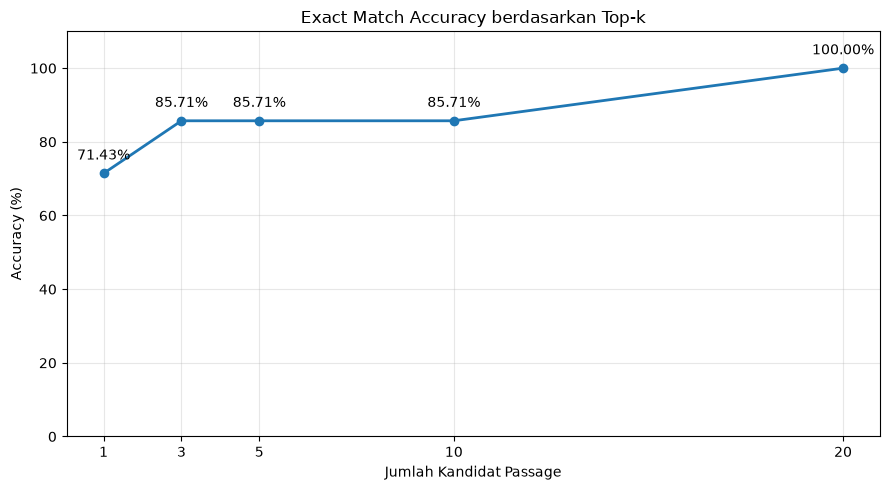

In [12]:
import matplotlib.pyplot as plt

x = [
    h["top_k"]
    for h in hasil_top_k
]

y = [
    h["accuracy"] * 100
    for h in hasil_top_k
]

plt.figure(figsize=(9, 5))

plt.plot(
    x,
    y,
    marker="o",
    linewidth=2
)

for a, b in zip(x, y):

    plt.annotate(
        f"{b:.2f}%",
        (a, b),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.title("Exact Match Accuracy berdasarkan Top-k")
plt.xlabel("Jumlah Kandidat Passage")
plt.ylabel("Accuracy (%)")

plt.xticks(x)
plt.ylim(0, 110)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

MRR

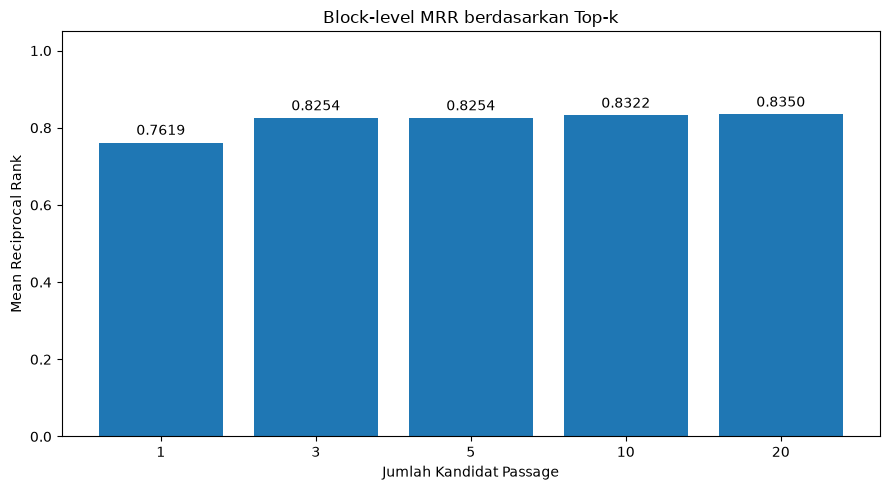

In [13]:
y_mrr = [
    h["mrr"]
    for h in hasil_top_k
]

plt.figure(figsize=(9, 5))

plt.bar(
    [str(k) for k in x],
    y_mrr
)

for i, nilai in enumerate(y_mrr):

    plt.text(
        i,
        nilai + 0.02,
        f"{nilai:.4f}",
        ha="center"
    )

plt.title("Block-level MRR berdasarkan Top-k")
plt.xlabel("Jumlah Kandidat Passage")
plt.ylabel("Mean Reciprocal Rank")

plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

Hit@k

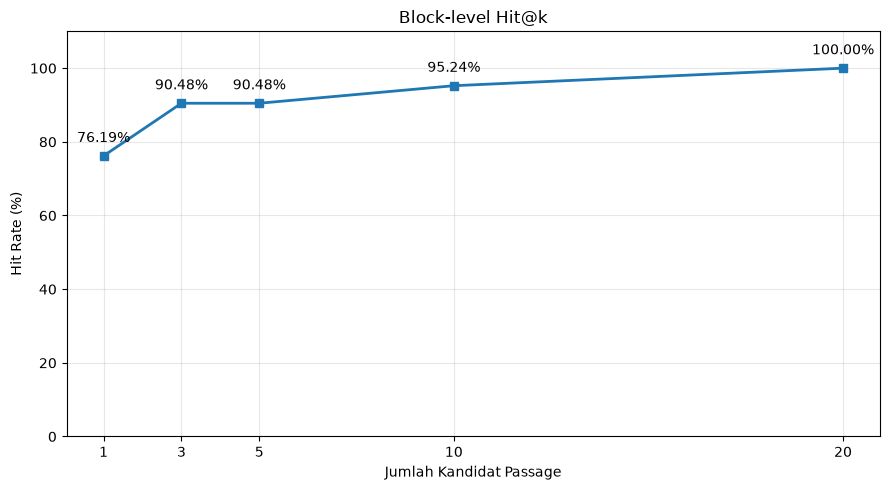

In [14]:
y_hit = [
    h["hit_at_k"] * 100
    for h in hasil_top_k
]

plt.figure(figsize=(9, 5))

plt.plot(
    x,
    y_hit,
    marker="s",
    linewidth=2
)

for a, b in zip(x, y_hit):

    plt.annotate(
        f"{b:.2f}%",
        (a, b),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.title("Block-level Hit@k")
plt.xlabel("Jumlah Kandidat Passage")
plt.ylabel("Hit Rate (%)")

plt.xticks(x)
plt.ylim(0, 110)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Analisis Kesalahan

In [15]:
K_ANALISIS = 5

hasil_analisis = evaluasi_sistem(
    SOAL_UJI,
    k=K_ANALISIS
)

jumlah_gagal = 0

for hasil in hasil_analisis:

    if not hasil["exact_match"]:

        jumlah_gagal += 1

        print("=" * 70)

        print(
            "Pertanyaan :",
            hasil["pertanyaan"]
        )

        print(
            "Acuan      :",
            hasil["jawaban_acuan"]
        )

        print(
            "Chatbot    :",
            hasil["jawaban_chatbot"]
        )

        print(
            "Blok Acuan :",
            hasil["blok_acuan"]
        )

        print(
            "ID Sumber  :",
            hasil["id_sumber"]
        )

        print(
            "Rank Blok  :",
            hasil["rank_relevan"]
        )

        if not hasil["hit"]:

            print(
                "Diagnosis awal: "
                "Blok acuan tidak ditemukan "
                "dalam kandidat retrieval."
            )

        else:

            print(
                "Diagnosis awal: "
                "Blok acuan ditemukan, "
                "tetapi jawaban belum sesuai."
            )

print("=" * 70)

print(f"Top-k          : {K_ANALISIS}")
print(f"Jumlah gagal   : {jumlah_gagal}")

Pertanyaan : Dimana masa persidangan pertama BPUPK dibuka?
Acuan      : Gedung Chuo Sangi In di Jakarta
Chatbot    : None
Blok Acuan : D02-B0010
ID Sumber  : None
Rank Blok  : None
Diagnosis awal: Blok acuan tidak ditemukan dalam kandidat retrieval.
Pertanyaan : Kapan Mohammad Hatta lahir?
Acuan      : 12 Agustus 1902
Chatbot    : None
Blok Acuan : D08-B0004
ID Sumber  : None
Rank Blok  : 1
Diagnosis awal: Blok acuan ditemukan, tetapi jawaban belum sesuai.
Pertanyaan : Dimana Fatmawati dilahirkan?
Acuan      : Bengkulu
Chatbot    : None
Blok Acuan : D11-B0002
ID Sumber  : None
Rank Blok  : None
Diagnosis awal: Blok acuan tidak ditemukan dalam kandidat retrieval.
Top-k          : 5
Jumlah gagal   : 3


In [16]:
SOAL_DIAGNOSTIK = [

    {
        "pertanyaan":
            "Kapan Moh. Hatta lahir?",

        "aspek":
            "Normalisasi alias"
    },

    {
        "pertanyaan":
            "Kapan Soekarno lahir?",

        "aspek":
            "Generalisasi ekstraksi tanggal"
    },

    {
        "pertanyaan":
            "Siapa wakil presiden pertama Indonesia?",

        "aspek":
            "Paraphrase"
    },

    {
        "pertanyaan":
            "Kapan Indonesia merdeka?",

        "aspek":
            "Validasi relasi"
    },

    {
        "pertanyaan":
            "Kapan Universitas Brawijaya didirikan?",

        "aspek":
            "Pertanyaan di luar domain"
    }
]

In [17]:
hasil_diagnostik = []

for soal in SOAL_DIAGNOSTIK:

    hasil = jawab_pertanyaan(
        soal["pertanyaan"],
        k=K
    )

    hasil_diagnostik.append({

        "pertanyaan":
            soal["pertanyaan"],

        "aspek":
            soal["aspek"],

        "query":
            hasil["query"],

        "jawaban_chatbot":
            hasil["jawaban"],

        "id_sumber":
            hasil["id_sumber"]
    })

    print("=" * 70)

    print("Aspek      :", soal["aspek"])
    print("Pertanyaan :", soal["pertanyaan"])
    print("Query      :", hasil["query"])
    print("Jawaban    :", hasil["jawaban"])
    print("ID Sumber  :", hasil["id_sumber"])

Aspek      : Normalisasi alias
Pertanyaan : Kapan Moh. Hatta lahir?
Query      : kapan mohammad hatta lahir?
Jawaban    : 12 Agustus 1902
ID Sumber  : D08-B0004-K003
Aspek      : Generalisasi ekstraksi tanggal
Pertanyaan : Kapan Soekarno lahir?
Query      : kapan soekarno lahir?
Jawaban    : None
ID Sumber  : None
Aspek      : Paraphrase
Pertanyaan : Siapa wakil presiden pertama Indonesia?
Query      : siapa wakil presiden pertama indonesia?
Jawaban    : Mohammad Hatta
ID Sumber  : D03-B0001-K002
Aspek      : Validasi relasi
Pertanyaan : Kapan Indonesia merdeka?
Query      : kapan indonesia merdeka?
Jawaban    : None
ID Sumber  : None
Aspek      : Pertanyaan di luar domain
Pertanyaan : Kapan Universitas Brawijaya didirikan?
Query      : kapan universitas brawijaya didirikan?
Jawaban    : None
ID Sumber  : None


## 10. Penyimpanan Hasil Evaluasi

In [ ]:
# Penamaan berdasarkan metode query
versi = (
    "normalized"
    if USE_NORMALIZED_QUERY
    else "baseline"
)

# Lokasi penyimpanan hasil evaluasi
OUTPUT_DIR = ROOT / "results" / versi

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Fungsi penyimpanan JSON
def simpan_json(data, nama_file):

    lokasi = OUTPUT_DIR / nama_file

    lokasi.write_text(
        json.dumps(
            data,
            ensure_ascii=False,
            indent=2
        ),
        encoding="utf-8"
    )

    print(f"Berhasil disimpan: {lokasi}")


# Fungsi penyimpanan CSV
def simpan_csv(data, nama_file):

    if not data:
        return

    lokasi = OUTPUT_DIR / nama_file

    with lokasi.open(
        "w",
        encoding="utf-8-sig",
        newline=""
    ) as file:

        penulis = csv.DictWriter(
            file,
            fieldnames=list(data[0].keys())
        )

        penulis.writeheader()
        penulis.writerows(data)

    print(f"Berhasil disimpan: {lokasi}")

In [ ]:
# Simpan hasil pengujian utama
simpan_json(
    hasil_akhir,
    f"hasil_evaluasi_{versi}_k{K}.json"
)

simpan_csv(
    hasil_akhir,
    f"hasil_evaluasi_{versi}_k{K}.csv"
)

# Simpan ringkasan evaluasi
simpan_json(
    ringkasan,
    f"ringkasan_evaluasi_{versi}.json"
)

# Simpan eksperimen Top-k
simpan_csv(
    hasil_top_k,
    f"eksperimen_top_k_{versi}.csv"
)

# Simpan hasil pengujian diagnostik
simpan_csv(
    hasil_diagnostik,
    f"hasil_diagnostik_{versi}.csv"
)

print("\nSeluruh hasil evaluasi berhasil disimpan.")